# ESP32 router CSI: amplitude and phase

Open this notebook in Jupyter or VS Code and run the cells in order. The saved
plots below were generated from the capture available when this notebook was created.
Rerun to analyze a newer capture.

**VS Code setup:** click **Select Kernel â†’ Python Environments â†’ Enter interpreter path**
and choose `E:\Espressif\tools\python\v6.1\venv\Scripts\python.exe` (ESP-IDF).
Then choose **Run All**. The notebook prints its Python executable so you can verify the kernel.

Install requirements from the ESP-IDF terminal, in this example folder, if needed:

```powershell
python -m pip install -r requirements-notebook.txt
```

Each CSV row is one packet. Each pair in `data` is **[imaginary, real]**;
`H = real + 1j * imaginary`, amplitude is `abs(H)`, and phase is `angle(H)`.
The original ESP32 example collects LLTF CSI. `first_word == 1` marks the first
four values (two complex samples) invalid; these are masked without shifting columns.

Column labels are **array pair indices**, not signed OFDM subcarrier numbers.
Null/guard bins are not mapped here; all-zero bins are hidden automatically.
Raw phase contains receiver timing/frequency offsets. Unwrapping removes 2Ï€ jumps
but does not calibrate phase or make it a direct measurement of distance or motion.

[Espressif CSI format reference](https://docs.espressif.com/projects/esp-idf/en/v5.0/esp32/api-guides/wifi.html#wi-fi-channel-state-information)


In [1]:
from pathlib import Path
from collections import Counter
import csv
import json
import sys
try:
    import numpy as np
    import matplotlib.pyplot as plt
except ImportError as error:
    raise ImportError(
        f"Notebook kernel: {sys.executable}\n"
        "Select the ESP-IDF Python environment in VS Code (Select Kernel), "
        "or run %pip install numpy matplotlib in this kernel and restart it."
    ) from error

print('Notebook Python:', sys.executable)
get_ipython().run_line_magic('matplotlib', 'inline')

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.2})

# None selects the newest CSV in captures/. Or provide an absolute file path.
CSV_PATH = "captures/csi_20261018_220301.csv"
# Optional array pair indices for the line plots, e.g. [6, 12, 20].
SELECTED_BINS = None

# VS Code may start a kernel in the workspace root, notebook folder,
# or another parent folder. Search these locations and their ancestors.
relative_example = Path('drafts/modeling_and_analysis')
candidates = []
for parent in (Path.cwd(), *Path.cwd().parents):
    candidates.extend([parent, parent / relative_example])
example_dir = next((p for p in candidates
                    if (p / 'capture_csi.py').is_file() and (p / 'captures').is_dir()), None)
def resolve_capture_path(value):
    requested = Path(value).expanduser()
    if requested.is_absolute():
        options = [requested]
    else:
        # Try the relative path from each ancestor rather than blindly
        # appending a repository-relative path to the notebook directory.
        options = [parent / requested for parent in (Path.cwd(), *Path.cwd().parents)]
        if example_dir:
            options.append(example_dir / requested)
    for option in options:
        if option.is_file():
            return option.resolve()
    raise FileNotFoundError(
        f'Capture not found: {value} (working directory: {Path.cwd()}). '
        'Set CSV_PATH to an existing absolute CSV path using a raw string: r"E:\\...\\file.csv".'
    )

if CSV_PATH is None:
    files = [p for p in (example_dir / 'captures').glob('*.csv') if p.stat().st_size > 0] if example_dir else []
    if not files:
        raise FileNotFoundError('No capture CSV found. Set CSV_PATH to an existing absolute CSV path.')
    csv_path = max(files, key=lambda p: p.stat().st_mtime).resolve()
else:
    csv_path = resolve_capture_path(CSV_PATH)
print('Capture:', csv_path)


Notebook Python: E:\Espressif\tools\python\v6.1\venv\Scripts\python.exe
Capture: E:\IOT\esp-csi\drafts\modeling_and_analysis\captures\csi_20261018_220301.csv


## Load and validate packets

This cell rejects malformed rows and chooses the most common combination of
CSI length, channel, bandwidth, and signal mode. Other combinations are reported
and excluded to keep incompatible measurements out of the same matrix.


In [2]:
records = []
invalid = 0
with csv_path.open(newline='', encoding='utf-8-sig') as stream:
    reader = csv.DictReader(stream)
    required = {'data', 'len', 'first_word', 'local_timestamp'}
    if not required.issubset(reader.fieldnames or []):
        raise ValueError(f'CSV must contain {sorted(required)}')
    for row in reader:
        if row.get('type', 'CSI_DATA') != 'CSI_DATA':
            continue
        try:
            values = json.loads(row['data'])
            if not isinstance(values, list) or not all(type(v) is int for v in values):
                raise ValueError('Invalid sample array')
            data = np.asarray(values, dtype=float)
            if data.size < 2 or data.size % 2 or data.size != int(row['len']):
                raise ValueError('Invalid length')
            timestamp = int(row['local_timestamp'])
            first_invalid = int(row['first_word'])
            if not 0 <= timestamp < 2**32 or first_invalid not in (0, 1):
                raise ValueError('Invalid metadata')
            group = (data.size, row.get('channel'), row.get('bandwidth'), row.get('sig_mode'))
            records.append((timestamp, first_invalid, data, group))
        except (ValueError, TypeError, KeyError):
            invalid += 1
if not records:
    raise ValueError('No valid CSI packets in this file.')
groups = Counter(record[3] for record in records)
chosen_group = groups.most_common(1)[0][0]
packets = [record for record in records if record[3] == chosen_group]
print('Packet groups (length, channel, bandwidth, signal mode):', dict(groups))
print(f'Using {len(packets)} packets; malformed rows: {invalid}; other formats: {len(records)-len(packets)}')

raw_time = np.array([r[0] for r in packets], dtype=np.int64)
deltas = np.diff(raw_time)
# A 32-bit microsecond clock wraps roughly every 71.6 minutes.
deltas = np.where(deltas < -(2**31), deltas + 2**32, deltas)
if np.any(deltas < 0):
    raise ValueError('Timestamp moved backwards: possible ESP32 reboot. Split the capture into sessions.')
time_s = np.r_[0, np.cumsum(deltas)] / 1e6
if len(time_s) < 2 or time_s[-1] <= 0:
    raise ValueError('At least two packets with distinct timestamps are needed.')

raw = np.stack([r[2] for r in packets])
H = raw[:, 1::2] + 1j * raw[:, 0::2]
bad_first = np.array([bool(r[1]) for r in packets])
H[bad_first, :2] = complex(np.nan, np.nan)
amplitude = np.abs(H)
all_zero_or_invalid = ~np.any(np.isfinite(amplitude) & (amplitude > 0), axis=0)
amplitude[:, all_zero_or_invalid] = np.nan
# Phase is undefined for zero magnitude samples.
phase = np.angle(H)
phase[(amplitude == 0) | ~np.isfinite(amplitude)] = np.nan
valid_bins = np.flatnonzero(np.any(np.isfinite(amplitude) & (amplitude > 0), axis=0))
if valid_bins.size == 0:
    raise ValueError('All CSI bins are invalid or zero.')

def unwrap_segments(values):
    result = np.full_like(values, np.nan)
    indices = np.flatnonzero(np.isfinite(values))
    for segment in np.split(indices, np.flatnonzero(np.diff(indices) > 1) + 1):
        if segment.size:
            result[segment] = np.unwrap(values[segment])
    return result

phase_unwrapped = np.column_stack([unwrap_segments(phase[:, k]) for k in range(H.shape[1])])
if SELECTED_BINS is None:
    selected = valid_bins[np.linspace(0, len(valid_bins)-1, min(3, len(valid_bins)), dtype=int)]
else:
    selected = np.asarray(SELECTED_BINS, dtype=int)
    if selected.size == 0 or not np.all(np.isin(selected, valid_bins)):
        raise ValueError(f'SELECTED_BINS must come from {valid_bins.tolist()}')
print(f'Duration: {time_s[-1]:.2f} s; average rate: {(len(time_s)-1)/time_s[-1]:.2f} packets/s')
print('Valid array pair indices:', valid_bins.tolist())
print('Selected indices:', selected.tolist())


Packet groups (length, channel, bandwidth, signal mode): {(128, '9', '0', '0'): 442}
Using 442 packets; malformed rows: 0; other formats: 0
Duration: 119.61 s; average rate: 3.69 packets/s
Valid array pair indices: [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63]
Selected indices: [2, 37, 63]


## Amplitude and wrapped phase across all bins

Each row of color shows one array pair index. Gaps indicate masked samples.
The horizontal axis uses device timestamps, including irregular packet spacing.
Amplitude is in receiver units, not dBm. Wrapped phase lies between âˆ’Ï€ and Ï€ radians.


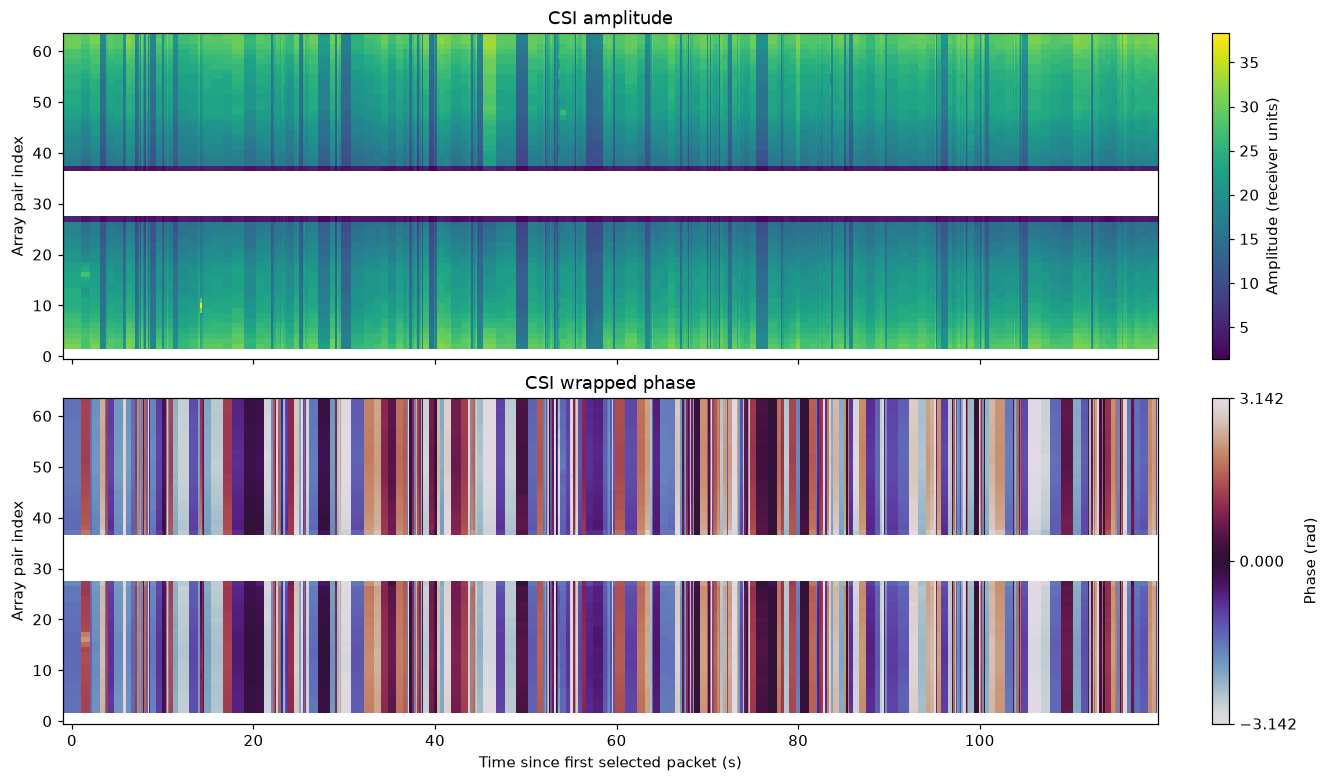

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout='constrained')
amp_plot = axes[0].pcolormesh(time_s, np.arange(H.shape[1]), amplitude.T,
                              shading='nearest', cmap='viridis', rasterized=True)
fig.colorbar(amp_plot, ax=axes[0], label='Amplitude (receiver units)')
axes[0].set(title='CSI amplitude', ylabel='Array pair index')
phase_plot = axes[1].pcolormesh(time_s, np.arange(H.shape[1]), phase.T,
                                shading='nearest', cmap='twilight',
                                vmin=-np.pi, vmax=np.pi, rasterized=True)
fig.colorbar(phase_plot, ax=axes[1], label='Phase (rad)', ticks=[-np.pi, 0, np.pi])
axes[1].set(title='CSI wrapped phase', xlabel='Time since first selected packet (s)',
            ylabel='Array pair index')
for ax in axes:
    ax.grid(False)
plt.show()


## Selected bins over time

Edit `SELECTED_BINS` in the first code cell and rerun to compare other bins.
The third panel unwraps phase along time separately for each bin, preserving missing samples.
With sparse packets or rapid phase changes, true phase evolution cannot be recovered
uniquely by unwrapping. Treat it as an exploratory plot.


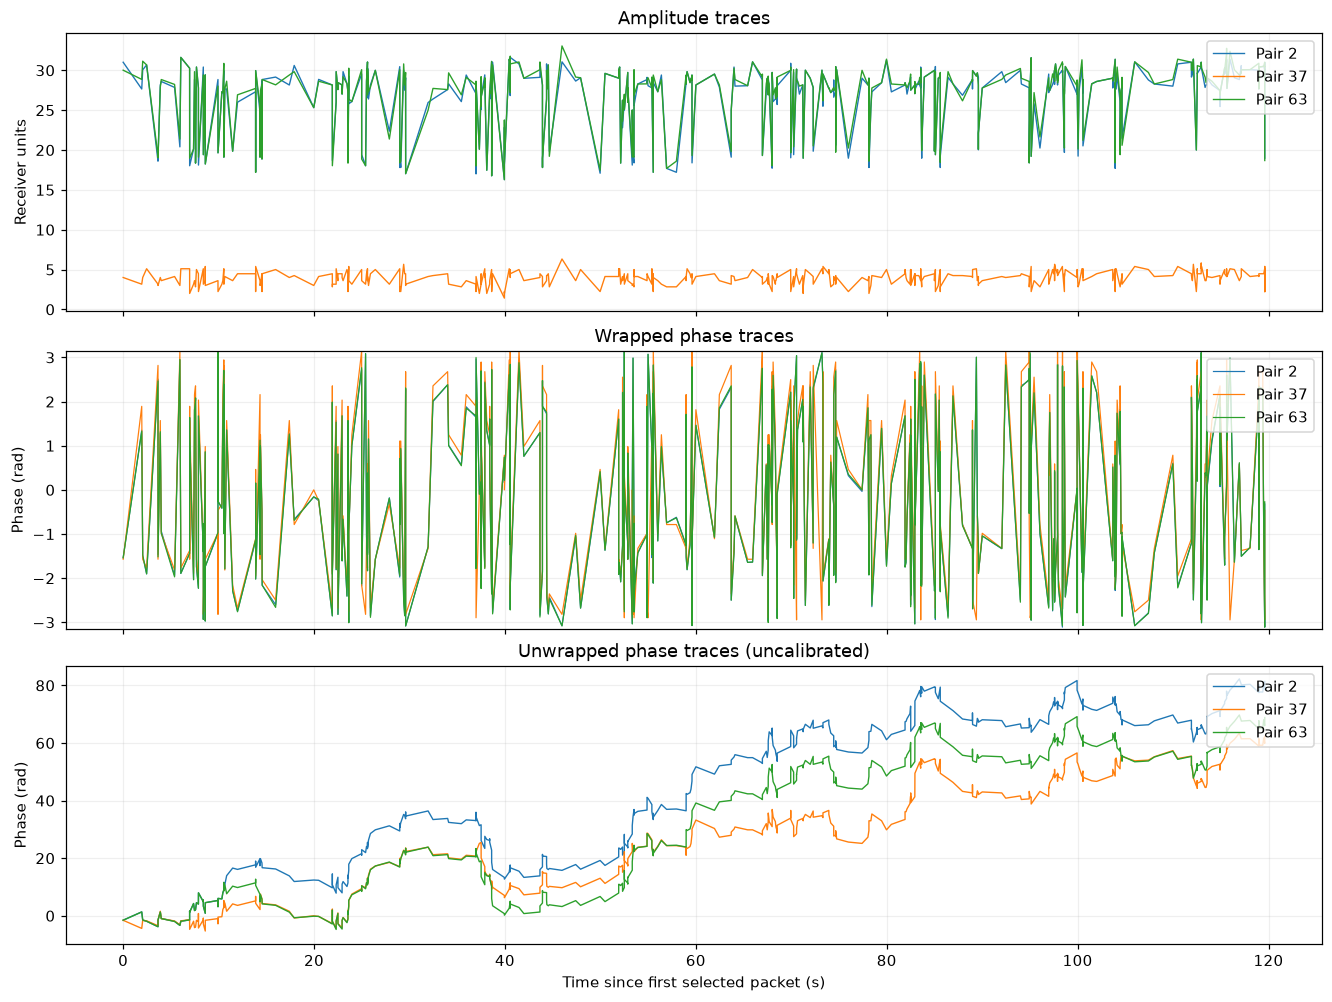

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, layout='constrained')
for k in selected:
    axes[0].plot(time_s, amplitude[:, k], label=f'Pair {k}', linewidth=0.9)
    axes[1].plot(time_s, phase[:, k], label=f'Pair {k}', linewidth=0.8)
    axes[2].plot(time_s, phase_unwrapped[:, k], label=f'Pair {k}', linewidth=0.9)
axes[0].set(title='Amplitude traces', ylabel='Receiver units')
axes[1].set(title='Wrapped phase traces', ylabel='Phase (rad)', ylim=(-np.pi, np.pi))
axes[2].set(title='Unwrapped phase traces (uncalibrated)', ylabel='Phase (rad)',
            xlabel='Time since first selected packet (s)')
for ax in axes:
    ax.legend(loc='upper right')
plt.show()


## One packet across bins

Change `PACKET_INDEX` to inspect a different packet. Pair indices remain in
the original buffer order; no FFT shift or signed-subcarrier mapping is applied.


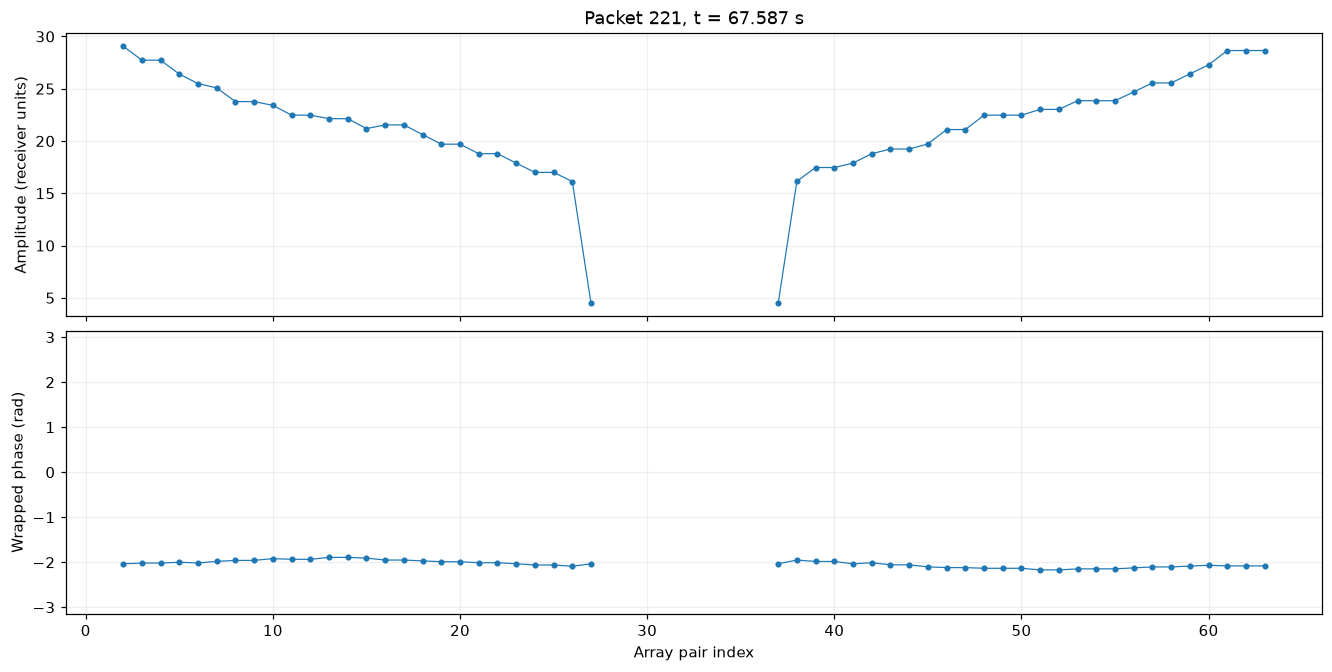

In [5]:
PACKET_INDEX = len(time_s) // 2
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, layout='constrained')
axes[0].plot(amplitude[PACKET_INDEX], '.-', linewidth=0.8)
axes[0].set(title=f'Packet {PACKET_INDEX}, t = {time_s[PACKET_INDEX]:.3f} s',
            ylabel='Amplitude (receiver units)')
axes[1].plot(phase[PACKET_INDEX], '.-', linewidth=0.8)
axes[1].set(xlabel='Array pair index', ylabel='Wrapped phase (rad)', ylim=(-np.pi, np.pi))
plt.show()


## Windowed features for presence experiments

These are **measurements to compare against labeled empty / walking / seated
recordings**, not a trained detector. No occupancy decision or breathing-rate
claim is produced. Raw phase features remain uncalibrated.

Defaults: **30-second complete windows, 5-second steps**. Shorter windows can
track motion faster, but do not contain enough cycles for slow periodicity.
Windows overlap; do not randomly split adjacent windows into training and test
sets, since they share packets. Split by recording session instead.

Features use the already masked `H` matrix and valid array pair indices.
Raw amplitude retains receiver-scale changes. Per-packet normalization divides
each bin's amplitude by the mean across valid bins; it reduces common scale
changes but can also remove real signal. Both versions are retained.


In [6]:
import importlib
import sys

module_dir = example_dir
if module_dir is None:
    raise FileNotFoundError('Run from the repository or notebook folder so csi_features.py can be found.')
if str(module_dir) not in sys.path:
    sys.path.insert(0, str(module_dir))
import csi_features
importlib.reload(csi_features)

WINDOW_SECONDS = 30.0
HOP_SECONDS = 5.0
MIN_PACKETS = 12
MAX_GAP_SECONDS = 2.0
PERIODIC_BAND_HZ = (0.1, 0.5)  # exploratory slow periodicity, not a diagnostic range
MIN_CYCLES = 3

feature_parameters = dict(window_seconds=WINDOW_SECONDS, hop_seconds=HOP_SECONDS,
    min_packets=MIN_PACKETS, max_gap_seconds=MAX_GAP_SECONDS,
    periodic_band=PERIODIC_BAND_HZ, min_cycles=MIN_CYCLES)
feature_rows = csi_features.extract_features(time_s, H, bins=valid_bins, **feature_parameters)
if not feature_rows:
    raise ValueError('Capture is shorter than WINDOW_SECONDS. Reduce it or record for longer.')
feature_time = np.array([r['window_center_s'] for r in feature_rows])
def feature_column(name):
    return np.array([r[name] for r in feature_rows], dtype=float)

print(f'{len(feature_rows)} complete windows of {WINDOW_SECONDS:g} s, step {HOP_SECONDS:g} s')
print('Windows passing gap/count checks:', sum(r['quality_ok'] for r in feature_rows))
print('Windows with periodicity estimates:', sum(r['periodicity_ok'] for r in feature_rows))
print('First window:')
for name, value in feature_rows[0].items():
    print(f'  {name}: {value}')


18 complete windows of 30 s, step 5 s
Windows passing gap/count checks: 3
Windows with periodicity estimates: 3
First window:
  window_start_s: 0.0
  window_end_s: 30.0
  window_center_s: 15.0
  packet_count: 104
  bin_count: 53
  imputed_fraction: 0.0
  packet_rate_hz: 3.4799801472200533
  max_gap_s: 2.0479589999999988
  quality_ok: False
  periodicity_ok: False
  amplitude_mean: 19.013614915820035
  amplitude_std_median: 3.5491957533790033
  amplitude_mad_median: 1.9181260887524356
  amplitude_cv_median: 0.18426440148803208
  amplitude_step_median: 2.000871440684284
  amplitude_change_rate_median: 67.54411296332636
  normalized_std_median: 0.021880741131596715
  normalized_step_median: 0.02022402518953048
  subcarrier_abs_correlation: 0.19884616717268414
  pca1_variance_fraction: 0.19807075116447048
  phase_step_abs_median_rad: 1.7852954785304491
  relative_phase_step_abs_median_rad: 0.025081763329982465
  periodic_peak_hz: nan
  periodic_explained_fraction: nan


### Feature definitions

| CSV field | Definition / interpretation |
|---|---|
| `amplitude_mean` | Mean across observed samples and bins; receiver units. |
| `amplitude_std_median` | Median across bins of temporal standard deviation. |
| `amplitude_mad_median` | Median across bins of temporal median absolute deviation (unscaled). |
| `amplitude_cv_median` | Median per-bin standard deviation divided by temporal mean. |
| `amplitude_step_median` | Median absolute amplitude change between adjacent packets. |
| `amplitude_change_rate_median` | Same change divided by actual elapsed seconds; receiver units/s. |
| `normalized_std_median`, `normalized_step_median` | Variability and changes after per-packet normalization; dimensionless. |
| `subcarrier_abs_correlation` | Mean absolute pairwise Pearson correlation of varying normalized bin traces. |
| `pca1_variance_fraction` | Fraction explained by the first principal component of standardized normalized traces. |
| `phase_step_abs_median_rad` | Median absolute circular phase increment between adjacent packets. |
| `relative_phase_step_abs_median_rad` | Same after subtracting the circular common increment across bins; **not full phase calibration**. |
| `periodic_peak_hz` | Frequency maximizing the median sinusoid-fit score across informative normalized bins. |
| `periodic_explained_fraction` | Median fraction of detrended temporal variance explained by that sinusoid; not a calibrated PSD or confidence probability. |

Periodicity fits sinusoids directly at **actual, irregular timestamps** after
linear detrending. At least `MIN_CYCLES` must fit within the observed span.
This avoids assuming the requested ping rate was achieved, but does not eliminate
sampling aliases. A periodic peak is not proof of respiration or human presence.

Bins need at least 80% valid samples in a window; all-zero bins are excluded.
Multivariate and spectral features fill remaining amplitude gaps with each bin's
median (`imputed_fraction` reports how much). Raw statistics ignore missing data;
packet differences ignore zero-duration pairs and gaps above `MAX_GAP_SECONDS`.
Phase is omitted at zero amplitude.

`quality_ok` requires enough packets and no excessive gaps, including the window
edges. Motion statistics remain visible for a poor-quality window; exclude those
windows when training. Periodicity is suppressed for poor quality or an inadequate
average packet rate. Blank CSV values mean unavailable, not zero.


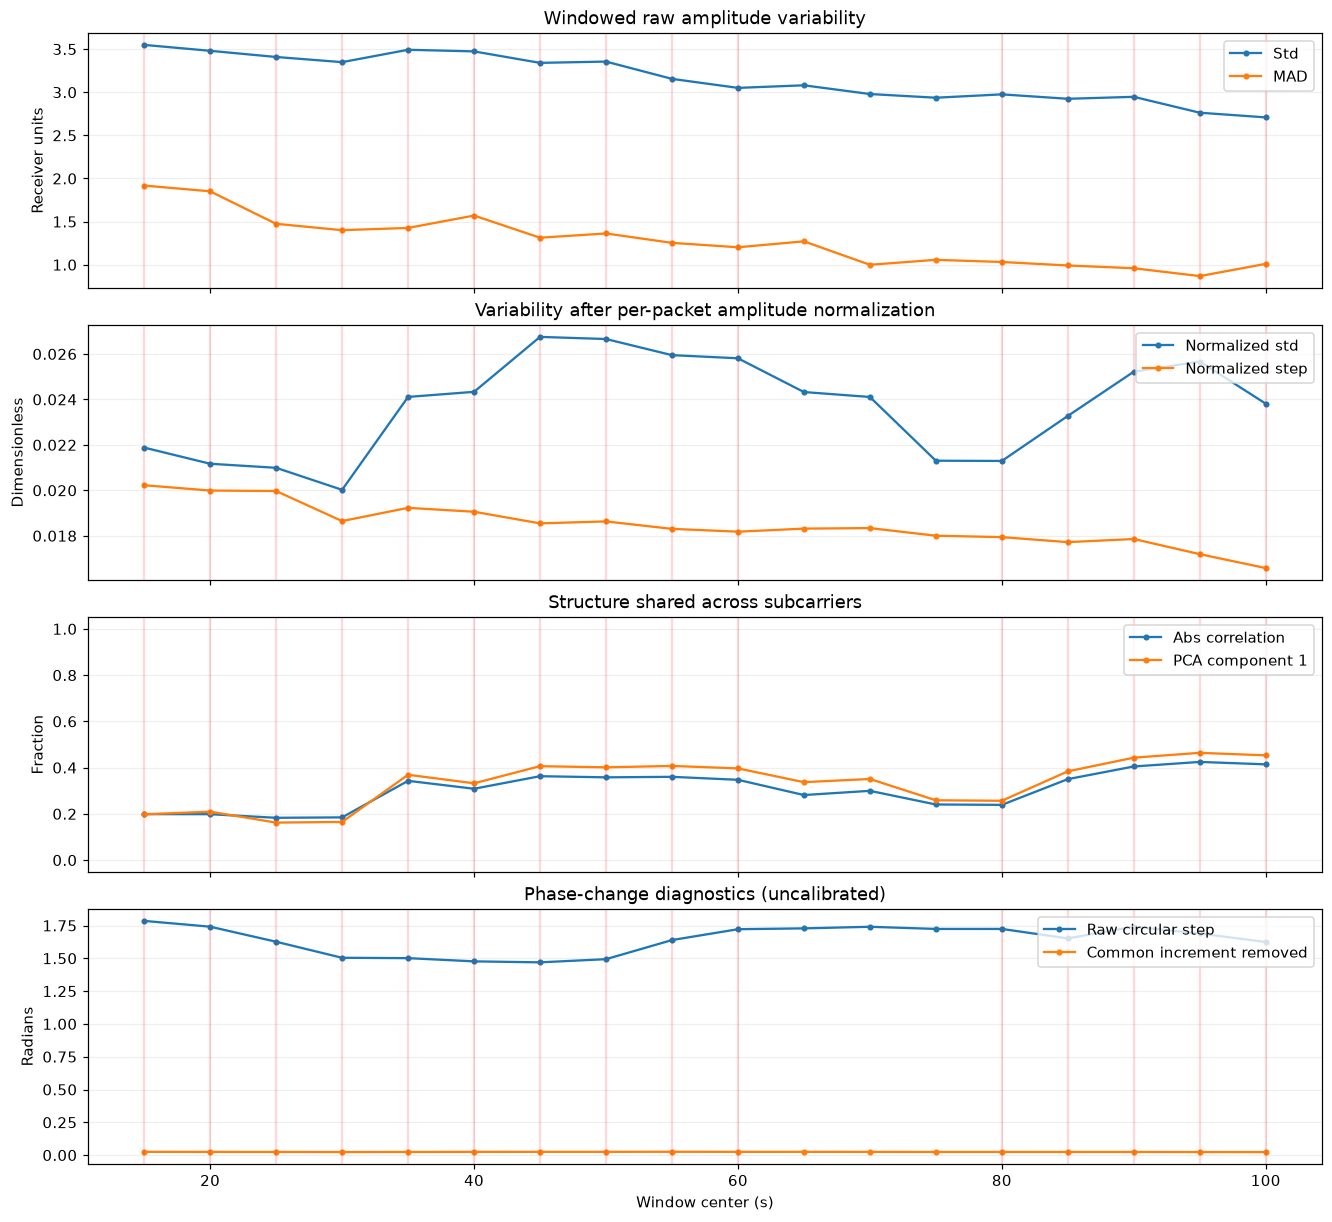

In [7]:
fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True, layout='constrained')
axes[0].plot(feature_time, feature_column('amplitude_std_median'), '.-', label='Std')
axes[0].plot(feature_time, feature_column('amplitude_mad_median'), '.-', label='MAD')
axes[0].set(title='Windowed raw amplitude variability', ylabel='Receiver units')
axes[1].plot(feature_time, feature_column('normalized_std_median'), '.-', label='Normalized std')
axes[1].plot(feature_time, feature_column('normalized_step_median'), '.-', label='Normalized step')
axes[1].set(title='Variability after per-packet amplitude normalization', ylabel='Dimensionless')
axes[2].plot(feature_time, feature_column('subcarrier_abs_correlation'), '.-', label='Abs correlation')
axes[2].plot(feature_time, feature_column('pca1_variance_fraction'), '.-', label='PCA component 1')
axes[2].set(title='Structure shared across subcarriers', ylabel='Fraction', ylim=(-0.05, 1.05))
axes[3].plot(feature_time, feature_column('phase_step_abs_median_rad'), '.-', label='Raw circular step')
axes[3].plot(feature_time, feature_column('relative_phase_step_abs_median_rad'), '.-', label='Common increment removed')
axes[3].set(title='Phase-change diagnostics (uncalibrated)', ylabel='Radians', xlabel='Window center (s)')
bad_quality = ~feature_column('quality_ok').astype(bool)
for ax in axes:
    for center in feature_time[bad_quality]:
        ax.axvline(center, color='red', alpha=0.15)
    ax.legend(loc='upper right')
plt.show()


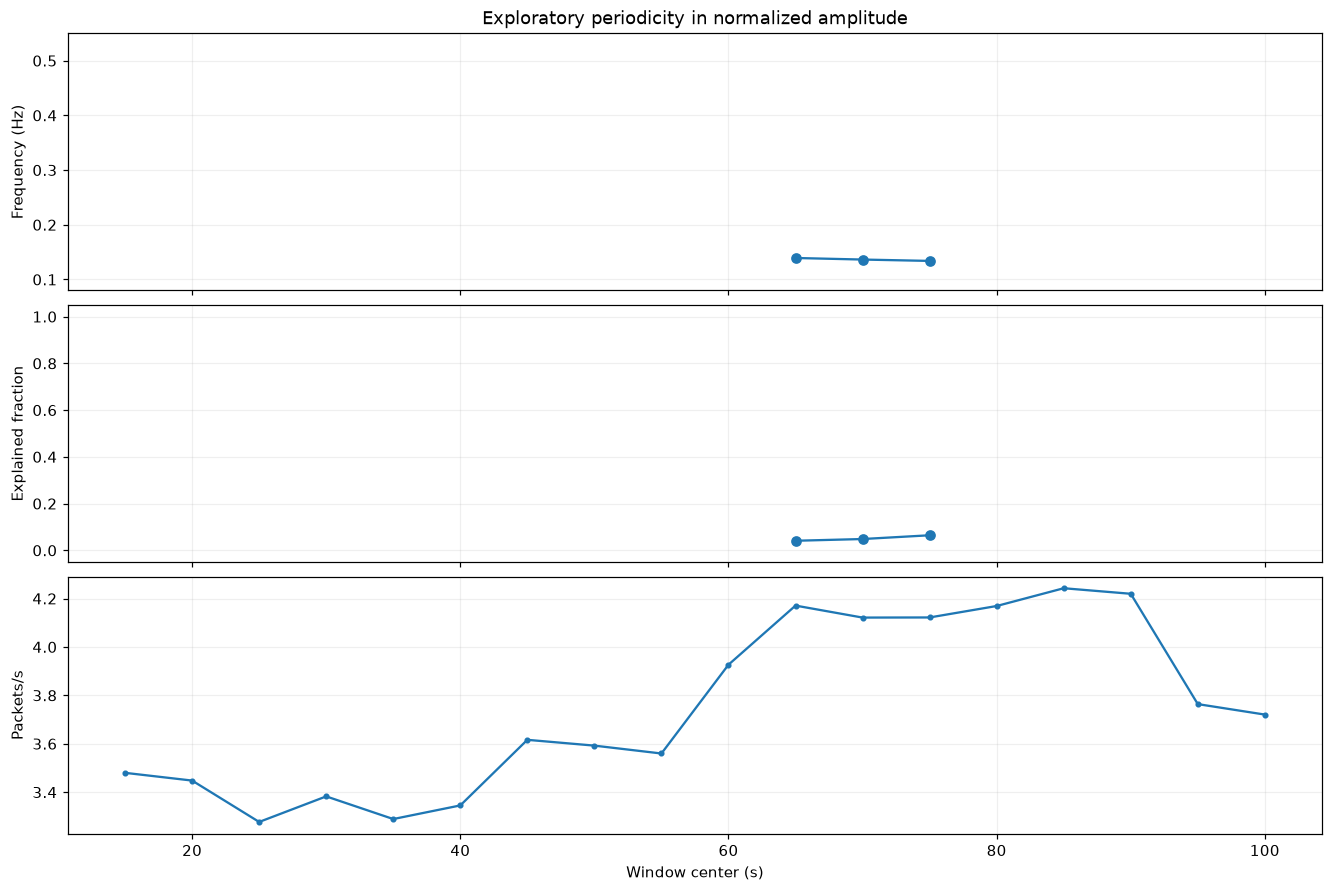

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, layout='constrained')
axes[0].plot(feature_time, feature_column('periodic_peak_hz'), 'o-', label='Slow-periodicity peak')
axes[0].set(title='Exploratory periodicity in normalized amplitude', ylabel='Frequency (Hz)',
            ylim=(PERIODIC_BAND_HZ[0]*0.8, PERIODIC_BAND_HZ[1]*1.1))
axes[1].plot(feature_time, feature_column('periodic_explained_fraction'), 'o-')
axes[1].set(ylabel='Explained fraction', ylim=(-0.05, 1.05))
axes[2].plot(feature_time, feature_column('packet_rate_hz'), '.-', label='Observed packets/s')
axes[2].set(ylabel='Packets/s', xlabel='Window center (s)')
for ax in axes:
    ax.grid(True, alpha=0.2)
if not any(r['periodicity_ok'] for r in feature_rows):
    axes[0].text(0.5, 0.5, 'No windows meet periodicity requirements',
                 transform=axes[0].transAxes, ha='center')
plt.show()


## Feature dashboard

Read the dashboard from top to bottom:

- **Heatmap:** each row is one feature across window centers. Colors are
  standardized **within this recording**: blue is below that feature's mean,
  red is above it. They do not indicate occupancy or compare physical units.
  Gray means unavailable; constant features are shown at zero.
- **Quality strip:** green windows pass sampling checks, red windows have
  inadequate sampling. The second row shows whether slow periodicity could
  be estimated. These are data-quality indicators, not presence labels.
- **Scatter plot:** raw versus normalized amplitude variability, colored by
  time. Crosses mark windows failing quality checks. This helps inspect whether
  large raw variations persist after removing common amplitude scaling.

Change `DASHBOARD_FEATURES` to choose which exported features to compare.
The dashboard is also saved as a PNG beside the exported feature CSV.


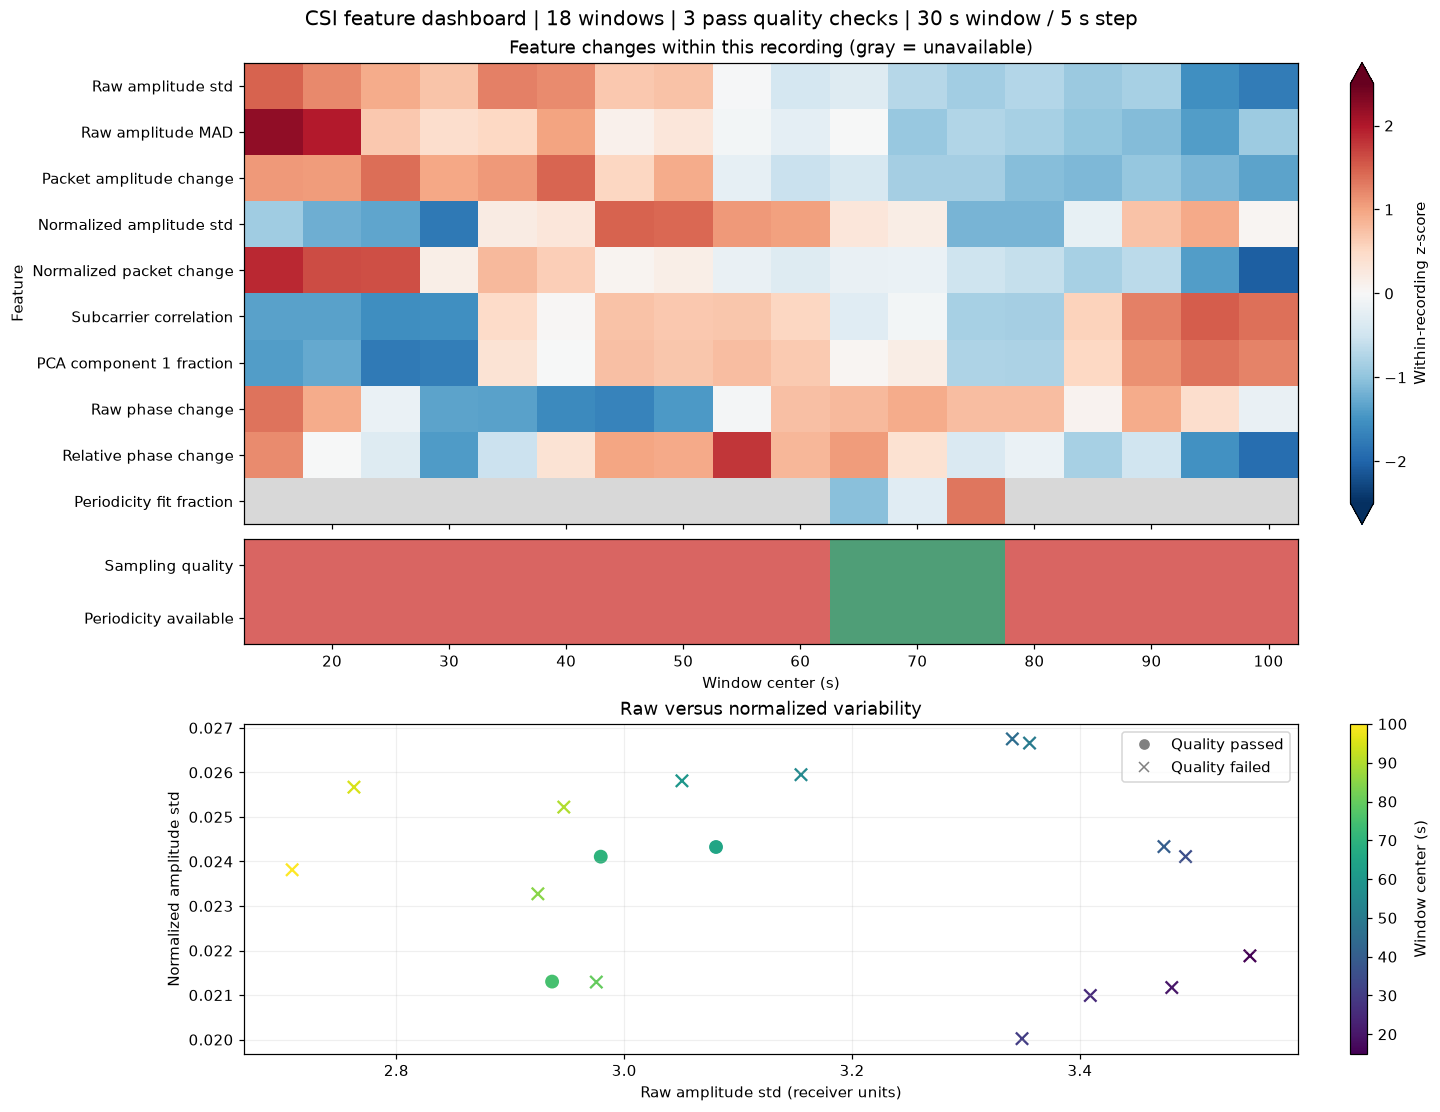

Saved dashboard: E:\IOT\esp-csi\drafts\modeling_and_analysis\captures\features\csi_20261018_220301_feature_dashboard.png


In [9]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D

DASHBOARD_FEATURES = [
    ('amplitude_std_median', 'Raw amplitude std'),
    ('amplitude_mad_median', 'Raw amplitude MAD'),
    ('amplitude_step_median', 'Packet amplitude change'),
    ('normalized_std_median', 'Normalized amplitude std'),
    ('normalized_step_median', 'Normalized packet change'),
    ('subcarrier_abs_correlation', 'Subcarrier correlation'),
    ('pca1_variance_fraction', 'PCA component 1 fraction'),
    ('phase_step_abs_median_rad', 'Raw phase change'),
    ('relative_phase_step_abs_median_rad', 'Relative phase change'),
    ('periodic_explained_fraction', 'Periodicity fit fraction'),
]
values = np.vstack([feature_column(name) for name, _ in DASHBOARD_FEATURES])
standardized = np.full_like(values, np.nan)
for index, values_row in enumerate(values):
    finite = np.isfinite(values_row)
    if finite.any():
        std = np.std(values_row[finite])
        standardized[index, finite] = ((values_row[finite] - np.mean(values_row[finite])) / std
                                        if std > 1e-12 else 0)

# Explicit cell edges work for both a single window and many windows.
time_edges = np.r_[feature_time - HOP_SECONDS/2, feature_time[-1] + HOP_SECONDS/2]
good_windows = feature_column('quality_ok').astype(bool)
periodic_windows = feature_column('periodicity_ok').astype(bool)
fig = plt.figure(figsize=(13, 10), layout='constrained')
grid = fig.add_gridspec(3, 1, height_ratios=[3.5, 0.8, 2.5])
heat_ax = fig.add_subplot(grid[0])
quality_ax = fig.add_subplot(grid[1], sharex=heat_ax)
scatter_ax = fig.add_subplot(grid[2])
fig.suptitle(
    f'CSI feature dashboard | {len(feature_rows)} windows | '
    f'{good_windows.sum()} pass quality checks | {WINDOW_SECONDS:g} s window / {HOP_SECONDS:g} s step',
    fontsize=13,
)

heat_cmap = plt.get_cmap('RdBu_r').copy()
heat_cmap.set_bad('#d8d8d8')
heat = heat_ax.pcolormesh(time_edges, np.arange(len(DASHBOARD_FEATURES)+1)-0.5,
    np.ma.masked_invalid(standardized), shading='flat', cmap=heat_cmap, vmin=-2.5, vmax=2.5)
heat_ax.set_yticks(np.arange(len(DASHBOARD_FEATURES)), [label for _, label in DASHBOARD_FEATURES])
heat_ax.invert_yaxis()
heat_ax.set(title='Feature changes within this recording (gray = unavailable)', ylabel='Feature')
heat_ax.tick_params(labelbottom=False)
heat_ax.grid(False)
fig.colorbar(heat, ax=heat_ax, label='Within-recording z-score', extend='both')

quality_cmap = ListedColormap(['#d96562', '#4f9e77'])
quality_norm = BoundaryNorm([-0.5, 0.5, 1.5], quality_cmap.N)
quality_ax.pcolormesh(time_edges, [-0.5, 0.5, 1.5],
    np.vstack([good_windows, periodic_windows]).astype(int),
    shading='flat', cmap=quality_cmap, norm=quality_norm)
quality_ax.set_yticks([0, 1], ['Sampling quality', 'Periodicity available'])
quality_ax.invert_yaxis()
quality_ax.set(xlabel='Window center (s)')
quality_ax.grid(False)

x = feature_column('amplitude_std_median')
y = feature_column('normalized_std_median')
finite = np.isfinite(x) & np.isfinite(y)
color_min, color_max = feature_time.min(), feature_time.max()
if color_min == color_max:
    color_max += HOP_SECONDS
color_norm = plt.Normalize(color_min, color_max)
for mask, marker in [(finite & good_windows, 'o'), (finite & ~good_windows, 'x')]:
    scatter_ax.scatter(x[mask], y[mask], c=feature_time[mask], cmap='viridis',
        norm=color_norm, marker=marker, s=65)
scatter_ax.set(title='Raw versus normalized variability',
    xlabel='Raw amplitude std (receiver units)', ylabel='Normalized amplitude std')
scatter_ax.legend(handles=[
    Line2D([], [], marker='o', linestyle='', color='gray', label='Quality passed'),
    Line2D([], [], marker='x', linestyle='', color='gray', label='Quality failed'),
], loc='best')
fig.colorbar(plt.cm.ScalarMappable(norm=color_norm, cmap='viridis'),
             ax=scatter_ax, label='Window center (s)')

dashboard_dir = csv_path.parent / 'features'
dashboard_dir.mkdir(parents=True, exist_ok=True)
dashboard_path = dashboard_dir / f'{csv_path.stem}_feature_dashboard.png'
fig.savefig(dashboard_path, dpi=160, bbox_inches='tight')
plt.show()
print('Saved dashboard:', dashboard_path)


### Export for comparison or machine learning

The next cell writes one row per window to `captures/features/<capture>_features.csv`
and saves the parameters beside it as JSON. Rerunning overwrites these derived
files, while the original capture is preserved. Add human-provided labels per
recording/session before training; do not infer labels from these features alone.


In [10]:
output_dir = csv_path.parent / 'features'
output_dir.mkdir(parents=True, exist_ok=True)
features_path = output_dir / f'{csv_path.stem}_features.csv'
parameters_path = output_dir / f'{csv_path.stem}_features_parameters.json'
with features_path.open('w', newline='', encoding='utf-8') as stream:
    writer = csv.DictWriter(stream, fieldnames=['source_capture', *feature_rows[0]])
    writer.writeheader()
    for row in feature_rows:
        clean = {key: ('' if isinstance(value, (float, np.floating)) and not np.isfinite(value) else value)
                 for key, value in row.items()}
        writer.writerow(dict(source_capture=csv_path.name, **clean))
parameters_path.write_text(json.dumps(dict(source_capture=str(csv_path),
    valid_pair_indices=valid_bins.tolist(), feature_parameters=feature_parameters,
    description='Exploratory window features, not occupancy labels or calibrated breathing estimates.'),
    indent=2), encoding='utf-8')
print('Saved:', features_path)
print('Parameters:', parameters_path)


Saved: E:\IOT\esp-csi\drafts\modeling_and_analysis\captures\features\csi_20261018_220301_features.csv
Parameters: E:\IOT\esp-csi\drafts\modeling_and_analysis\captures\features\csi_20261018_220301_features_parameters.json
